<a href="https://colab.research.google.com/github/HanneV09/groepswerk_large_scale_analysis_groep_28/blob/main/LSABD_groepswerk_part2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf


# Helper-functie om CSV-bestanden slim te zoeken of via iPad-uploadknop te vragen
def load_csv_file(filename_keyword):
  matches = glob.glob(f"**/*{filename_keyword}*.csv", recursive=True)
  if matches:
    path = matches[0]  # Pak het eerste gevonden bestand als tekst
    print(f"✅ Bestand gevonden: '{path}'")
    return pd.read_csv(path)

  print(f"\n⚠️ '{filename_keyword}' niet direct gevonden in Colab memory.")
  print(f"👉 Selecteer '{filename_keyword}.csv' vanaf je iPad:")
  from google.colab import files

  uploaded = files.upload()
  uploaded_filename = list(uploaded.keys())[0]
  return pd.read_csv(uploaded_filename)


# 1. Metadata inladen
print("--- STAP 1A: Metadata laden ---")
df_meta = load_csv_file("sample_metadata")

# 2. Eiwitdata inladen
print("\n--- STAP 1B: Eiwitdata laden ---")
if "CXCL13" in df_meta.columns:
  df_merged = df_meta.copy()
  print("✅ CXCL13 staat direct in de metadata-file.")
else:
  df_npx = load_csv_file("proteins_npx_raw")
  if "sample_kit_id" in df_npx.columns and "sample_kit_id" in df_meta.columns:
    df_merged = pd.merge(df_meta, df_npx, on="sample_kit_id")
  else:
    df_merged = pd.concat([df_meta, df_npx], axis=1)

print(f"\n🎉 Totale gecombineerde dataset geladen! Vorm: {df_merged.shape}")

--- STAP 1A: Metadata laden ---
✅ Bestand gevonden: 'sample_metadata.csv'

--- STAP 1B: Eiwitdata laden ---
✅ Bestand gevonden: 'proteins_npx_raw 4.csv'

🎉 Totale gecombineerde dataset geladen! Vorm: (867, 1557)


In [ ]:
# 1. Filteren op de twee relevante tijdspunten voor griepvaccinatie
flu_visits = ["Flu Year 1 Day 0", "Flu Year 1 Day 7"]
df_flu = df_merged[df_merged["sample.visitName"].isin(flu_visits)].copy()

# 2. Kolomnamen met punten hernoemen naar schone namen voor statsmodels
df_flu = df_flu.rename(
    columns={
        "sample.visitName": "visit",
        "subject.ageGroup": "age_group",
        "subject.biologicalSex": "sex",
    }
)

# 3. Korte controle van het aantal observaties
print("Aantal stalen per tijdstip en leeftijdsgroep:")
print(pd.crosstab(df_flu["visit"], df_flu["age_group"]))
print(f"\nTotaal aantal stalen voor de regressie-analyse: {len(df_flu)}")

Aantal stalen per tijdstip en leeftijdsgroep:
age_group         Older Adult  Young Adult
visit                                     
Flu Year 1 Day 0           45           47
Flu Year 1 Day 7           45           47

Totaal aantal stalen voor de regressie-analyse: 184


In [ ]:
# Multivariabel OLS model fitten met interactie en confounder-correcties:
# - Referentie Visit: 'Flu Year 1 Day 0'
# - Referentie AgeGroup: 'Young Adult'
model_cxcl13 = smf.ols(
    "CXCL13 ~ C(visit, Treatment('Flu Year 1 Day 0')) * C(age_group,"
    " Treatment('Young Adult')) + C(sex) + C(cmv_status)",
    data=df_flu,
).fit()

# Print het volledige statistische overzicht voor jullie rapport
print("=" * 78)
print("STATISTISCHE RESULTATEN (PART 2 - MULTIVARIABELE OLS REGRESSIE)")
print("=" * 78)
print(model_cxcl13.summary())

STATISTISCHE RESULTATEN (PART 2 - MULTIVARIABELE OLS REGRESSIE)
                            OLS Regression Results                            
Dep. Variable:                 CXCL13   R-squared:                       0.106
Model:                            OLS   Adj. R-squared:                  0.081
Method:                 Least Squares   F-statistic:                     4.208
Date:                Thu, 26 Nov 2026   Prob (F-statistic):            0.00122
Time:                        09:06:41   Log-Likelihood:                -198.36
No. Observations:                 184   AIC:                             408.7
Df Residuals:                     178   BIC:                             428.0
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                                                                                        coef    std err          t

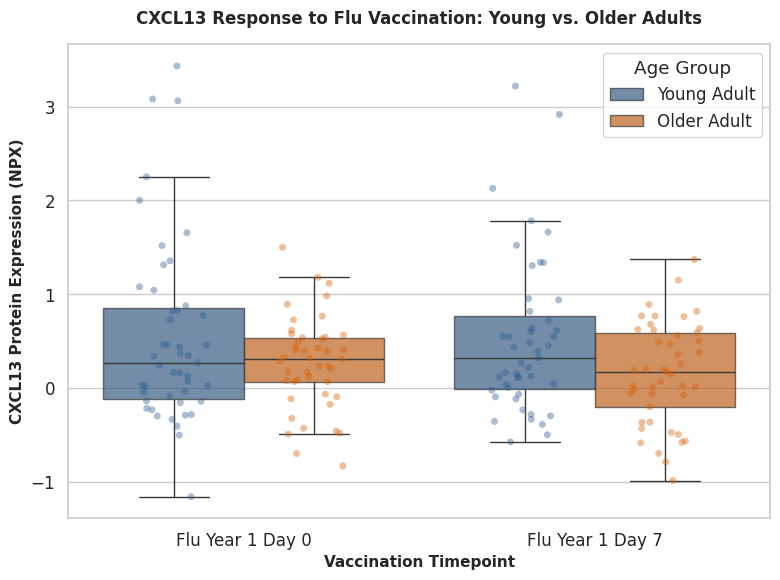


🎉 Grafiek succesvol gegenereerd en opgeslagen als 'cxcl13_vaccine_response.png'!


In [ ]:
# Visualisatiestijl instellen
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.figure(figsize=(8, 6))

# Kleurenpalet voor de twee leeftijdsgroepen
palette = {"Young Adult": "#2b5c8f", "Older Adult": "#d95f02"}

# Boxplot voor de verdeling per groep
sns.boxplot(
    data=df_flu,
    x="visit",
    y="CXCL13",
    hue="age_group",
    palette=palette,
    boxprops=dict(alpha=0.7),
    showfliers=False,
)

# Stripplot voor de individuele stalen/punten
sns.stripplot(
    data=df_flu,
    x="visit",
    y="CXCL13",
    hue="age_group",
    palette=palette,
    dodge=True,
    jitter=0.2,
    alpha=0.4,
    size=5,
    legend=False,
)

# As-labels en titel instellen
plt.title(
    "CXCL13 Response to Flu Vaccination: Young vs. Older Adults",
    fontsize=12,
    weight="bold",
    pad=15,
)
plt.xlabel("Vaccination Timepoint", fontsize=11, weight="bold")
plt.ylabel("CXCL13 Protein Expression (NPX)", fontsize=11, weight="bold")
plt.legend(title="Age Group", frameon=True)

plt.tight_layout()

# Afbeelding opslaan in hoge resolutie (300 DPI) voor GitHub en Word
plt.savefig("cxcl13_vaccine_response.png", dpi=300)
plt.show()

print(
    "\n🎉 Grafiek succesvol gegenereerd en opgeslagen als"
    " 'cxcl13_vaccine_response.png'!"
)